# CrossModalVAE3 Evaluation
Daimon (D) / eFlesh (E) / FlexiTac (F) — tri-modal pair-only training  
Evaluates:
1. **μ 임베딩 추출** — 세 pair의 val split에서 μ 추출
2. **t-SNE** — D/E/F 세 모달리티를 같은 공간에 시각화
3. **Cosine similarity 분포** — 직접 학습 pair(DE, EF, FD) + transitive pair(DF)
4. **Cross-modal retrieval** — top-1/5/10 (DE, EF, FD, DF)
5. **Reconstruction 시각화** — Daimon self/cross recon 샘플

In [2]:
import os, sys
import yaml
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm
from torch.utils.data import DataLoader
from sklearn.manifold import TSNE
import sklearn

sys.path.insert(0, os.getcwd())
from joint_embedding_learning.utils.models_setup import get_model
from joint_embedding_learning.data.datasets import get_all_contrastive_datasets

# ── 설정 ─────────────────────────────────────────────────
device        = "cuda:0"
dataset_name  = "dataset_cross_modal_tri_object"
objects       = ["cylinder", "plug"]          # 학습에 사용한 object 목록
model_name    = "cross_modal_vae3"
run_name      = "dataset_cross_modal_tri_object_run_tri_cyl_plug_20260510_192216"
BATCH_SIZE    = 64

checkpoint_dir = os.path.join("checkpoints", "cross_modal_tri", model_name, run_name)

# ── config 로드 ───────────────────────────────────────────
with open(os.path.join("config", "datasets_config.yaml")) as f:
    dataset_details = yaml.safe_load(f)[dataset_name]
with open(os.path.join(checkpoint_dir, "model_details.yaml")) as f:
    model_details = yaml.safe_load(f)

# ── 모델 로드 ─────────────────────────────────────────────
model = get_model(model_name, model_details).to(device)
ckpt_path = os.path.join(checkpoint_dir, "model.pt")
model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False))
model.eval()
print(f"Loaded: {ckpt_path}")
n_param = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_param:,}")

# ── 데이터셋 로드 (80/20 val split, cylinder + plug만) ────
train_datasets, val_datasets, _ = get_all_contrastive_datasets(
    dataset_name, data_split="train", device="cpu", objects=objects
)
print("Objects:", objects)
print("Train sizes:", {k: len(v) for k, v in train_datasets.items()})
print("Val sizes:",   {k: len(v) for k, v in val_datasets.items()})

Loaded: checkpoints/cross_modal_tri/cross_modal_vae3/dataset_cross_modal_tri_object_run_tri_cyl_plug_20260510_192216/model.pt
Parameters: 15,416,467
Val sizes: {'de': 0, 'ef': 0, 'fd': 0}


In [ ]:
# ===== 임베딩 추출 =====
@torch.no_grad()
def extract_pair_mu(dataset, pair_name, model, device, batch_size=128):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, drop_last=False)
    all_mu_a, all_mu_b = [], []
    for (xa, xb), _ in tqdm(loader, desc=pair_name):
        out = model.forward_pair(xa.to(device), xb.to(device), pair_name)
        all_mu_a.append(out["mu_a"].cpu())
        all_mu_b.append(out["mu_b"].cpu())
    return torch.cat(all_mu_a), torch.cat(all_mu_b)

# Train
mu_D_de_tr, mu_E_de_tr = extract_pair_mu(train_datasets["de"], "de", model, device)
mu_E_ef_tr, mu_F_ef_tr = extract_pair_mu(train_datasets["ef"], "ef", model, device)
mu_F_fd_tr, mu_D_fd_tr = extract_pair_mu(train_datasets["fd"], "fd", model, device)

# Val
mu_D_de_v, mu_E_de_v = extract_pair_mu(val_datasets["de"], "de", model, device)
mu_E_ef_v, mu_F_ef_v = extract_pair_mu(val_datasets["ef"], "ef", model, device)
mu_F_fd_v, mu_D_fd_v = extract_pair_mu(val_datasets["fd"], "fd", model, device)

print("Done.")

fd: 100%|██████████| 6/6 [00:00<00:00,  8.84it/s]

Done.


Pair              pos_mean   neg_mean   gap
--------------------------------------------------
DE (direct)        +0.9423    +0.0258    0.9165
EF (direct)        +0.9431    +0.1085    0.8346
FD (direct)        +0.9613    +0.0214    0.9399
DF (transitive)    +0.6858    +0.1073    0.5785


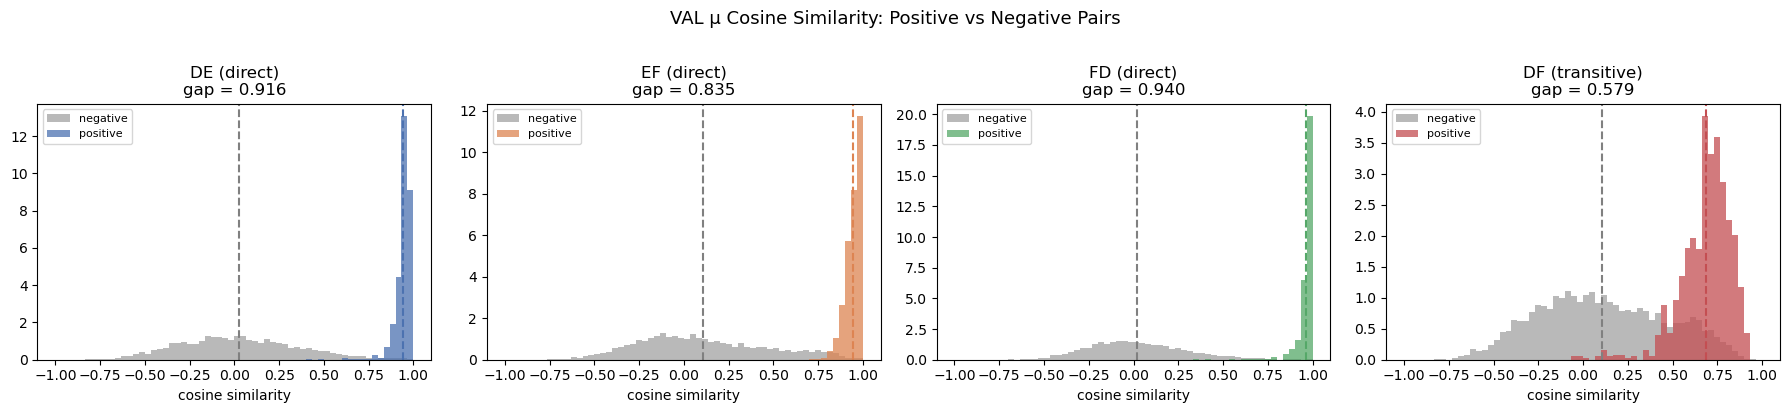

In [5]:
# ===== Cosine similarity 분포 (VAL) =====
def cosine_pos_neg(mu_a, mu_b, sample_neg=5000):
    """Diagonal = positive pairs; random off-diagonal = negatives."""
    a = F.normalize(mu_a, dim=1)
    b = F.normalize(mu_b, dim=1)
    pos = (a * b).sum(dim=1).cpu().numpy()

    N = a.shape[0]
    idx_a = np.random.randint(0, N, sample_neg)
    idx_b = np.random.randint(0, N, sample_neg)
    same = idx_a == idx_b
    idx_b[same] = (idx_b[same] + 1) % N
    neg = (a[idx_a] * b[idx_b]).sum(dim=1).cpu().numpy()
    return pos, neg

def transitive_df_cosine(mu_D_de, mu_E_de, mu_E_ef, mu_F_ef, sample_neg=5000):
    """Transitive D-F: match via nearest eFlesh neighbor."""
    e_de_n = F.normalize(mu_E_de, dim=1)
    e_ef_n = F.normalize(mu_E_ef, dim=1)

    sim_e = e_ef_n @ e_de_n.t()      # (N_ef, N_de)
    nn_idx = sim_e.argmax(dim=1)     # for each EF sample -> nearest DE sample
    mu_D_match = mu_D_de[nn_idx]     # matched D from DE side

    d_n = F.normalize(mu_D_match, dim=1)
    f_n = F.normalize(mu_F_ef, dim=1)

    pos = (d_n * f_n).sum(dim=1).cpu().numpy()

    N = d_n.shape[0]
    idx_a = np.random.randint(0, N, sample_neg)
    idx_b = np.random.randint(0, N, sample_neg)
    same = idx_a == idx_b
    idx_b[same] = (idx_b[same] + 1) % N
    neg = (d_n[idx_a] * f_n[idx_b]).sum(dim=1).cpu().numpy()
    return pos, neg

np.random.seed(0)

# ---- VAL 변수 사용 ----
pos_de, neg_de = cosine_pos_neg(mu_D_de_v, mu_E_de_v)
pos_ef, neg_ef = cosine_pos_neg(mu_E_ef_v, mu_F_ef_v)
pos_fd, neg_fd = cosine_pos_neg(mu_F_fd_v, mu_D_fd_v)
pos_df, neg_df = transitive_df_cosine(mu_D_de_v, mu_E_de_v, mu_E_ef_v, mu_F_ef_v)

pairs_data = [
    ("DE (direct)",     pos_de, neg_de, "#4C72B0"),
    ("EF (direct)",     pos_ef, neg_ef, "#DD8452"),
    ("FD (direct)",     pos_fd, neg_fd, "#55A868"),
    ("DF (transitive)", pos_df, neg_df, "#C44E52"),
]

print("Pair              pos_mean   neg_mean   gap")
print("-" * 50)
for label, pos, neg, _ in pairs_data:
    print(f"{label:<18} {pos.mean():+.4f}    {neg.mean():+.4f}    {pos.mean()-neg.mean():.4f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
bins = np.linspace(-1, 1, 61)

for ax, (label, pos, neg, color) in zip(axes, pairs_data):
    ax.hist(neg, bins=bins, alpha=0.55, color="gray", label="negative", density=True)
    ax.hist(pos, bins=bins, alpha=0.75, color=color, label="positive", density=True)
    ax.axvline(pos.mean(), color=color, linestyle="--", linewidth=1.5)
    ax.axvline(neg.mean(), color="gray", linestyle="--", linewidth=1.5)
    ax.set_title(f"{label}\ngap = {pos.mean()-neg.mean():.3f}")
    ax.set_xlabel("cosine similarity")
    ax.legend(fontsize=8)

plt.suptitle("VAL μ Cosine Similarity: Positive vs Negative Pairs", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("eval_results/cross_modal_vae3_cosine_dist_val.png", dpi=150, bbox_inches="tight")
plt.show()

[Train] t-SNE on 19598 points (DE:2601×2, EF:4513×2, FD:2685×2) ...


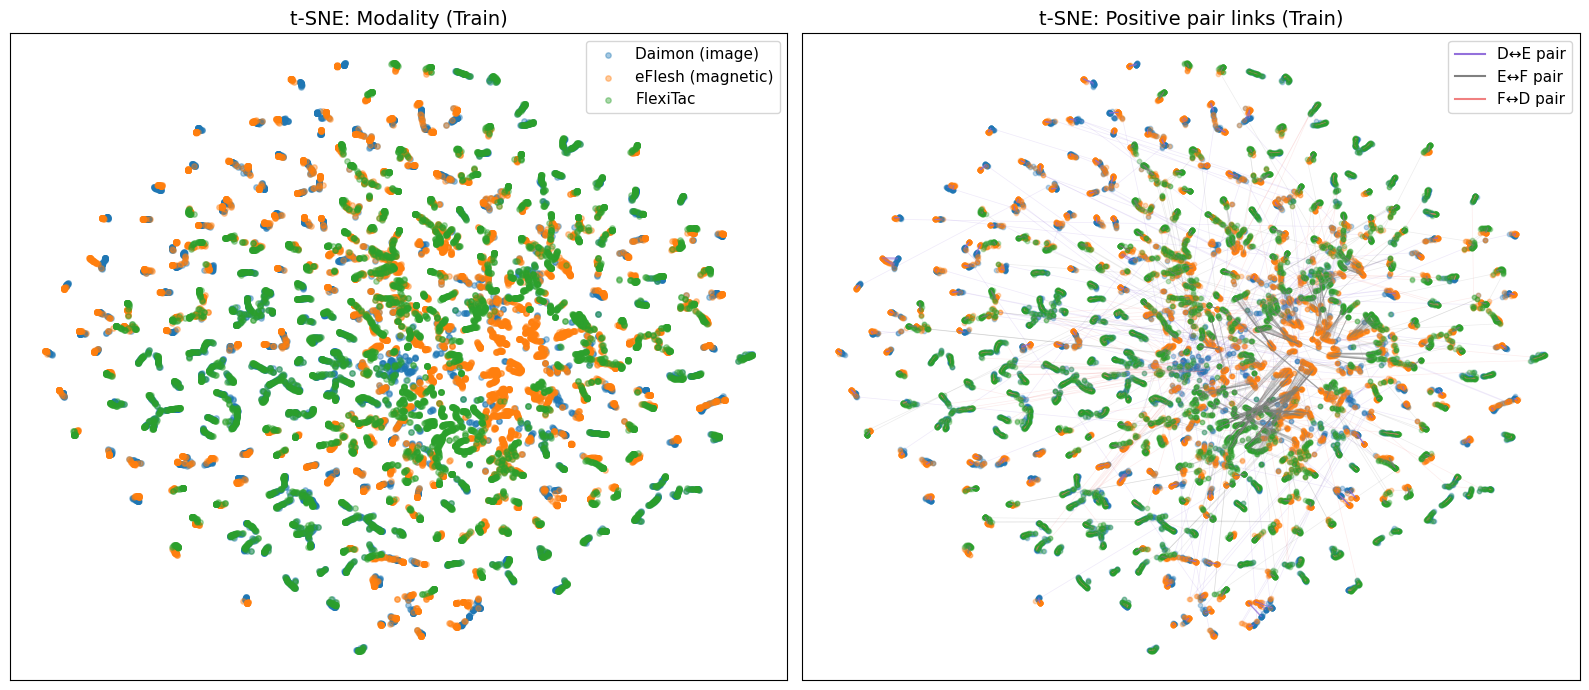

Saved: eval_results/cross_modal_vae3_tsne_train.png
[Val] t-SNE on 4904 points (DE:651×2, EF:1129×2, FD:672×2) ...


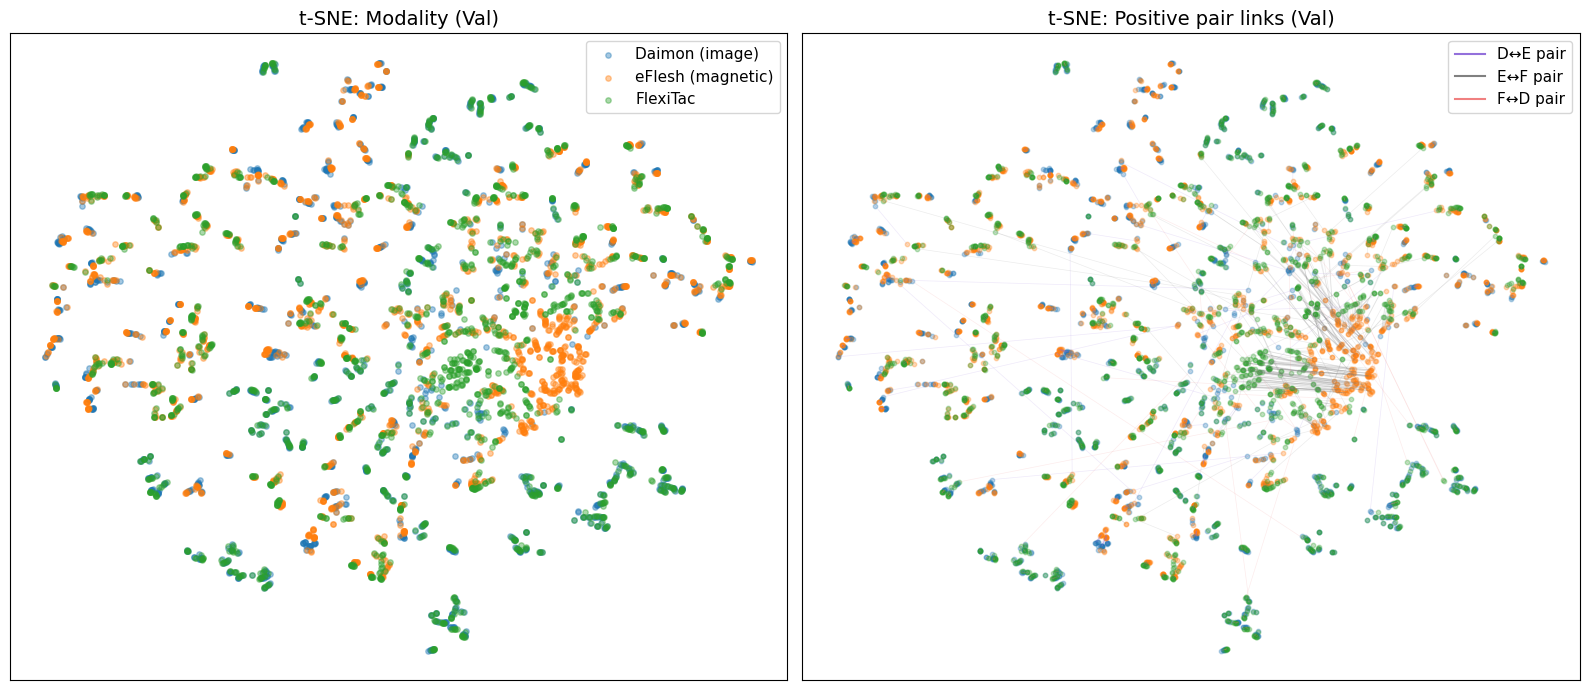

Saved: eval_results/cross_modal_vae3_tsne_val.png


In [6]:
# ===== t-SNE 시각화 =====
# pair 단위로 aligned 임베딩 유지 → positive line은 같은 에피소드/프레임 매칭
#
# 구조:
#   de_pair → (D_de[i], E_de[i])  같은 에피소드·프레임
#   ef_pair → (E_ef[i], F_ef[i])  같은 에피소드·프레임
#   fd_pair → (F_fd[i], D_fd[i])  같은 에피소드·프레임
#
# 모든 임베딩을 t-SNE에 넣고, pair 내 같은 인덱스끼리 선을 그림

def make_tsne(points, perplexity=30, seed=42):
    kw = dict(n_components=2, perplexity=perplexity, random_state=seed)
    if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 0):
        kw["max_iter"] = 1000
    else:
        kw["n_iter"] = 1000
    return TSNE(**kw).fit_transform(points)


def plot_tsne_pairs(mu_D_de, mu_E_de, mu_E_ef, mu_F_ef, mu_F_fd, mu_D_fd,
                    split_name, save_path, n_lines=10**9):
    """
    6개 임베딩 블록을 concat하여 t-SNE 수행.
    positive line은 pair 내 같은 인덱스(=같은 에피소드/프레임)끼리 연결.
    """
    z_D_de = F.normalize(mu_D_de, dim=1).numpy()
    z_E_de = F.normalize(mu_E_de, dim=1).numpy()
    z_E_ef = F.normalize(mu_E_ef, dim=1).numpy()
    z_F_ef = F.normalize(mu_F_ef, dim=1).numpy()
    z_F_fd = F.normalize(mu_F_fd, dim=1).numpy()
    z_D_fd = F.normalize(mu_D_fd, dim=1).numpy()

    n_de, n_ef, n_fd = len(z_D_de), len(z_E_ef), len(z_F_fd)

    combined = np.concatenate([z_D_de, z_E_de, z_E_ef, z_F_ef, z_F_fd, z_D_fd], axis=0)
    print(f"[{split_name}] t-SNE on {combined.shape[0]} points "
          f"(DE:{n_de}×2, EF:{n_ef}×2, FD:{n_fd}×2) ...")
    tsne_2d = make_tsne(combined)

    # 각 블록의 t-SNE 좌표 분리
    off = 0
    t_D_de = tsne_2d[off:off+n_de]; off += n_de
    t_E_de = tsne_2d[off:off+n_de]; off += n_de
    t_E_ef = tsne_2d[off:off+n_ef]; off += n_ef
    t_F_ef = tsne_2d[off:off+n_ef]; off += n_ef
    t_F_fd = tsne_2d[off:off+n_fd]; off += n_fd
    t_D_fd = tsne_2d[off:off+n_fd]; off += n_fd

    # 모달리티별로 모아서 scatter
    all_D = np.concatenate([t_D_de, t_D_fd])
    all_E = np.concatenate([t_E_de, t_E_ef])
    all_F = np.concatenate([t_F_ef, t_F_fd])

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # --- Plot 1: 모달리티별 색상 ---
    ax = axes[0]
    ax.scatter(all_D[:, 0], all_D[:, 1], c="tab:blue",   alpha=0.4, s=15, label="Daimon (image)")
    ax.scatter(all_E[:, 0], all_E[:, 1], c="tab:orange", alpha=0.4, s=15, label="eFlesh (magnetic)")
    ax.scatter(all_F[:, 0], all_F[:, 1], c="tab:green",  alpha=0.4, s=15, label="FlexiTac")
    ax.set_title(f"t-SNE: Modality ({split_name})", fontsize=14)
    ax.legend(fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

    # --- Plot 2: Positive pair 연결선 (같은 에피소드/프레임) ---
    ax = axes[1]
    ax.scatter(all_D[:, 0], all_D[:, 1], c="tab:blue",   alpha=0.3, s=10, label="Daimon")
    ax.scatter(all_E[:, 0], all_E[:, 1], c="tab:orange", alpha=0.3, s=10, label="eFlesh")
    ax.scatter(all_F[:, 0], all_F[:, 1], c="tab:green",  alpha=0.3, s=10, label="FlexiTac")

    rng = np.random.RandomState(0)

    # DE pair: D_de[i] ↔ E_de[i]
    idx_de = rng.choice(n_de, size=min(n_lines, n_de), replace=False)
    for k in idx_de:
        ax.plot([t_D_de[k, 0], t_E_de[k, 0]],
                [t_D_de[k, 1], t_E_de[k, 1]], c="mediumpurple", alpha=0.15, linewidth=0.5)

    # EF pair: E_ef[i] ↔ F_ef[i]
    idx_ef = rng.choice(n_ef, size=min(n_lines, n_ef), replace=False)
    for k in idx_ef:
        ax.plot([t_E_ef[k, 0], t_F_ef[k, 0]],
                [t_E_ef[k, 1], t_F_ef[k, 1]], c="gray", alpha=0.15, linewidth=0.5)

    # FD pair: F_fd[i] ↔ D_fd[i]
    idx_fd = rng.choice(n_fd, size=min(n_lines, n_fd), replace=False)
    for k in idx_fd:
        ax.plot([t_F_fd[k, 0], t_D_fd[k, 0]],
                [t_F_fd[k, 1], t_D_fd[k, 1]], c="lightcoral", alpha=0.15, linewidth=0.5)

    from matplotlib.lines import Line2D
    handles = [
        Line2D([], [], color="mediumpurple", lw=1.5, label="D↔E pair"),
        Line2D([], [], color="gray",         lw=1.5, label="E↔F pair"),
        Line2D([], [], color="lightcoral",   lw=1.5, label="F↔D pair"),
    ]
    ax.legend(handles=handles, fontsize=11)
    ax.set_title(f"t-SNE: Positive pair links ({split_name})", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")


os.makedirs("eval_results", exist_ok=True)

# ── Train ──
plot_tsne_pairs(
    mu_D_de_tr, mu_E_de_tr, mu_E_ef_tr, mu_F_ef_tr, mu_F_fd_tr, mu_D_fd_tr,
    "Train", "eval_results/cross_modal_vae3_tsne_train.png",
)

# ── Val ──
plot_tsne_pairs(
    mu_D_de_v, mu_E_de_v, mu_E_ef_v, mu_F_ef_v, mu_F_fd_v, mu_D_fd_v,
    "Val", "eval_results/cross_modal_vae3_tsne_val.png",
)

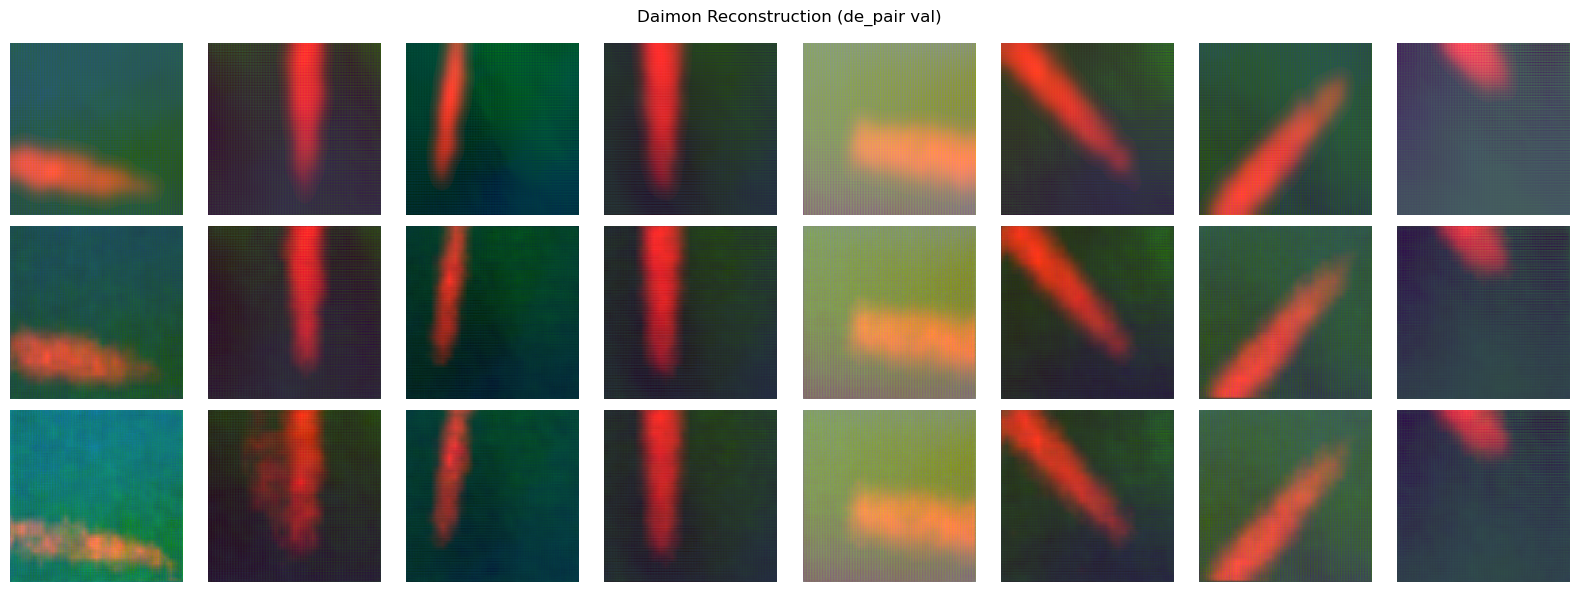

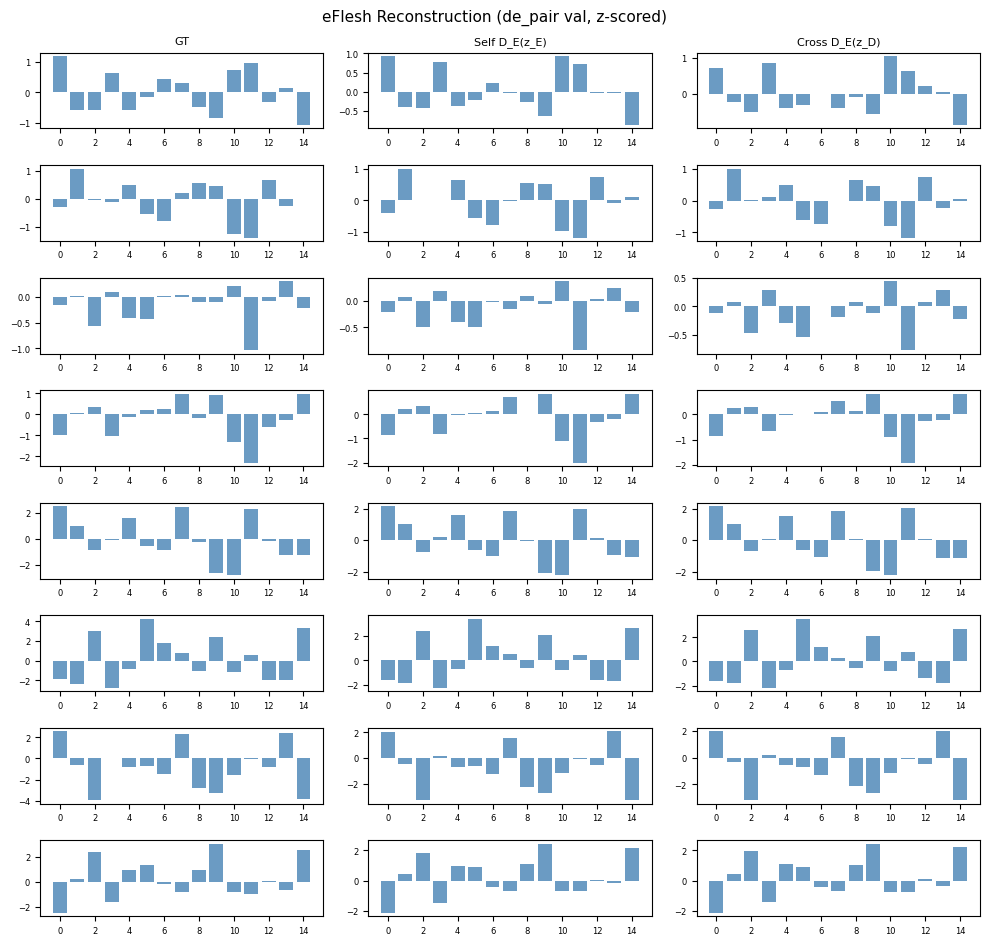

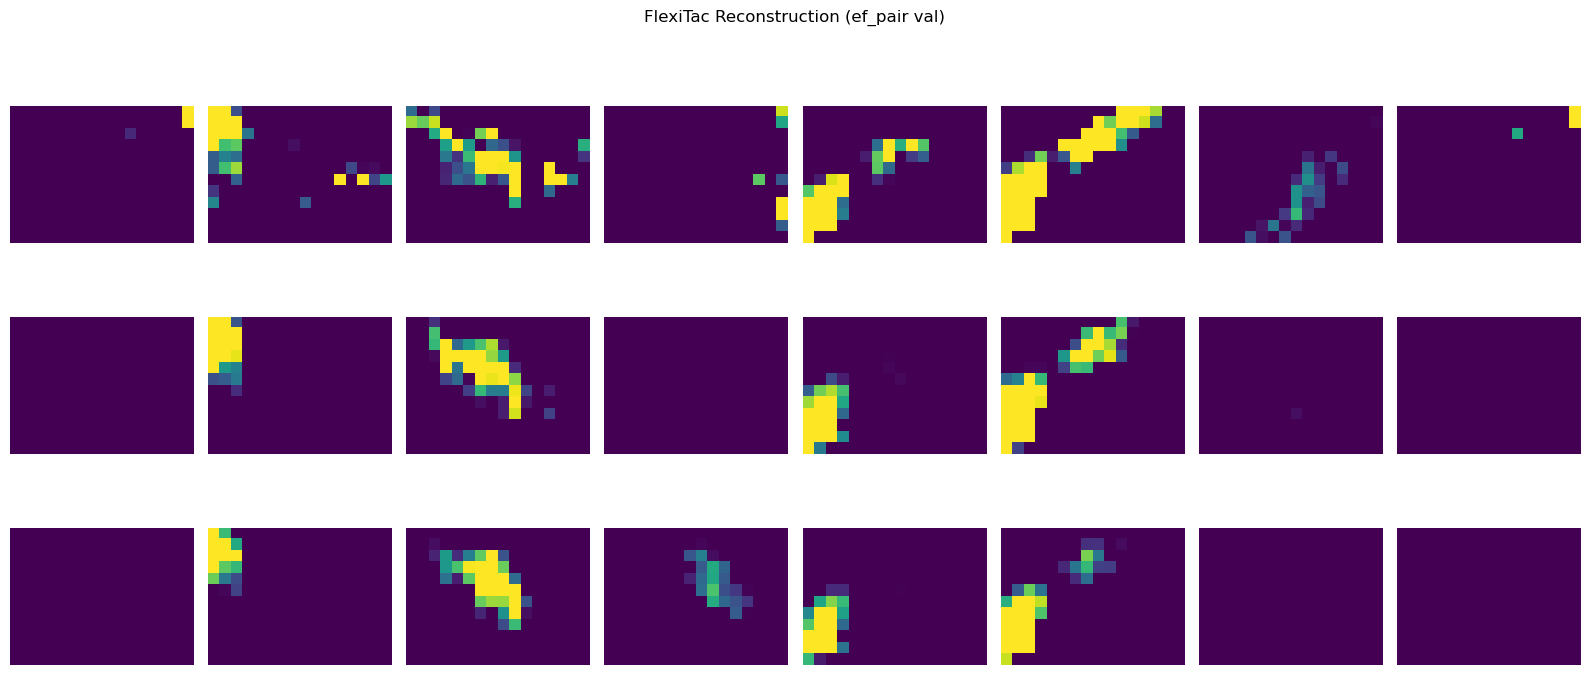

In [7]:
# ── Reconstruction 시각화 ─────────────────────────────────
# de_pair val에서 8 샘플: Daimon self-recon, cross-recon (E→D)
N_VIS = 8
val_de_loader = DataLoader(val_datasets["de"], batch_size=N_VIS, shuffle=True, drop_last=True)
(xa, xb), _ = next(iter(val_de_loader))
xa_dev = xa.to(device); xb_dev = xb.to(device)

with torch.no_grad():
    out = model.forward_pair(xa_dev, xb_dev, "de")

# Daimon normalization stats for denormalize
d_mean = torch.tensor(dataset_details["daimon_stats"]["mean"]).view(3, 1, 1)
d_std  = torch.tensor(dataset_details["daimon_stats"]["std"]).view(3, 1, 1)

def denorm(x):
    return (x.cpu() * d_std + d_mean).clamp(0, 1)

def to_vis(x):
    """Normalize to [0,1] for display regardless of input range."""
    x = x.cpu().float()
    mn, mx = x.min(), x.max()
    return ((x - mn) / (mx - mn + 1e-8)).clamp(0, 1)

rows = ["GT (Daimon)", "Self-recon D(z_D)→D", "Cross-recon D(z_E)→D"]
imgs = [
    [to_vis(xa[i]) for i in range(N_VIS)],
    [to_vis(out["recon_aa"][i].cpu()) for i in range(N_VIS)],
    [to_vis(out["recon_ba"][i].cpu()) for i in range(N_VIS)],
]

fig, axes = plt.subplots(3, N_VIS, figsize=(N_VIS * 2, 3 * 2))
for r, (row_label, row_imgs) in enumerate(zip(rows, imgs)):
    for c, img in enumerate(row_imgs):
        ax = axes[r, c]
        if img.shape[0] == 3:
            ax.imshow(img.permute(1, 2, 0).numpy())
        else:
            ax.imshow(img.squeeze().numpy(), cmap="gray")
        ax.axis("off")
        if c == 0:
            ax.set_ylabel(row_label, fontsize=8)
plt.suptitle("Daimon Reconstruction (de_pair val)", fontsize=12)
plt.tight_layout()
plt.savefig("eval_results/cross_modal_vae3_recon_daimon.png", dpi=150, bbox_inches="tight")
plt.show()

# ── eFlesh reconstruction ─────────────────────────────────
eflesh_gt   = xb[:N_VIS].cpu().numpy()           # (N, 15)
eflesh_self = out["recon_bb"][:N_VIS].cpu().numpy()  # D_E(z_E)
eflesh_cross= out["recon_ab"][:N_VIS].cpu().numpy()  # D_E(z_D)

fig, axes = plt.subplots(N_VIS, 3, figsize=(10, N_VIS * 1.2))
for i in range(N_VIS):
    for j, (arr, title) in enumerate([
            (eflesh_gt[i],    "GT"),
            (eflesh_self[i],  "Self D_E(z_E)"),
            (eflesh_cross[i], "Cross D_E(z_D)"),
    ]):
        axes[i, j].bar(range(15), arr, color="steelblue", alpha=0.8)
        if i == 0: axes[i, j].set_title(title, fontsize=8)
        axes[i, j].tick_params(labelsize=6)
plt.suptitle("eFlesh Reconstruction (de_pair val, z-scored)", fontsize=11)
plt.tight_layout()
plt.savefig("eval_results/cross_modal_vae3_recon_eflesh.png", dpi=150, bbox_inches="tight")
plt.show()

# ── FlexiTac reconstruction (ef_pair) ─────────────────────
val_ef_loader = DataLoader(val_datasets["ef"], batch_size=N_VIS, shuffle=True, drop_last=True)
(xe, xf), _ = next(iter(val_ef_loader))
xe_dev = xe.to(device); xf_dev = xf.to(device)
with torch.no_grad():
    out_ef = model.forward_pair(xe_dev, xf_dev, "ef")

flexi_gt    = xf[:N_VIS].cpu()                         # (N, 12, 16)
flexi_self  = out_ef["recon_bb"][:N_VIS].cpu().squeeze(1)  # (N, 12, 16)
flexi_cross = out_ef["recon_ab"][:N_VIS].cpu().squeeze(1)  # (N, 12, 16)

fig, axes = plt.subplots(3, N_VIS, figsize=(N_VIS * 2, 3 * 2.5))
for c in range(N_VIS):
    for r, (arr, title) in enumerate([
            (flexi_gt[c].numpy(),    "GT FlexiTac"),
            (flexi_self[c].numpy(),  "Self D_F(z_F)"),
            (flexi_cross[c].numpy(), "Cross D_F(z_E)"),
    ]):
        ax = axes[r, c]
        ax.imshow(arr, cmap="viridis", vmin=0, vmax=1)
        ax.axis("off")
        if c == 0: ax.set_ylabel(title, fontsize=8)
plt.suptitle("FlexiTac Reconstruction (ef_pair val)", fontsize=12)
plt.tight_layout()
plt.savefig("eval_results/cross_modal_vae3_recon_flexi.png", dpi=150, bbox_inches="tight")
plt.show()